# HW2 Part 1: Data Cleaning & Validation

**Gobind Singh**

This notebook takes the dirty `ohlc_hw` table, diagnoses its data-quality problems, repairs what can be repaired with evidence, quarantines what cannot, and saves the result as `ohlc_hw_cleaned` in `data/data.db`.

Run it from `Homeworks/HW2/GOBIND_SINGH/` with the course environment. It recreates every table it writes on each run, and it never modifies the raw `ohlc_hw` table or the reference `ohlc` table.

1. Load and inspect the data
2. Detect data-quality issues and build the Data Quality Report
3. Clean the data, with demonstrations on small injected examples
4. Validate, save, and compare before and after

In [1]:
import html
import re
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

DB_PATH = Path("data/data.db")
RAW_TABLE = "ohlc_hw"              # dirty input; read only
REFERENCE_TABLE = "ohlc"           # supplied table: trading calendar and adjustment factors
CLEAN_TABLE = "ohlc_hw_cleaned"
QUARANTINE_TABLE = "ohlc_hw_quarantine"
REPORT_TABLE = "ohlc_hw_quality_report"
AUDIT_TABLE = "ohlc_hw_ticker_audit"

RAW_PRICE_COLS = ["open", "high", "low", "close"]
PRICE_COLS = RAW_PRICE_COLS + ["adj_close"]
VALUE_COLS = ["ts", "ticker"] + PRICE_COLS + ["volume"]
KEY = ["ticker", "ts"]

OUTLIER_K = 3            # flag |r - mean| > 3 * std within each ticker
ADJ_FACTOR_WINDOW = 21   # trading days in the centred rolling median of adj_close / close
ADJ_SPIKE_RATIO = 2.0    # a factor more than 2x away from its local median is an error
FACTOR_CHANGE_TOL = 0.05 # a >5% day-over-day factor move suggests a corporate-action adjustment
REFERENCE_TOL = 0.01     # a close >1% away from the reference close disagrees with it

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"{DB_PATH.resolve()} not found. Copy the bCourses data.db into a data/ folder next to this notebook."
    )


def read_table(name):
    """Read a whole table from the course database."""
    with closing(sqlite3.connect(DB_PATH)) as conn:
        return pd.read_sql_query(f"SELECT * FROM {name}", conn)


def table_fingerprint(df):
    """Row count plus an order-independent content hash, used to prove a table was not modified."""
    return len(df), int(pd.util.hash_pandas_object(df, index=False).sum())

## 1.1 Load and inspect the data

| Column | Meaning |
|---|---|
| `ts` | Trading date (stored as text) |
| `ticker` | Stock symbol. Dirty: many labels are wrapped in HTML markup |
| `open`, `high`, `low`, `close` | Daily raw prices as delivered by the vendor. The OHLC bounds checks apply to these |
| `adj_close` | Vendor close adjusted for splits and dividends. Part 2 uses it for returns and drawdown |
| `volume` | Shares traded that day |

The reference table `ohlc` has the same columns. I use it only as the trading calendar and as a source of date-specific adjustment factors, never as a wholesale replacement for the dirty data.

In [2]:
raw = read_table(RAW_TABLE)
reference = read_table(REFERENCE_TABLE)
raw_fingerprint = table_fingerprint(raw)

print(f"{RAW_TABLE}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"{REFERENCE_TABLE}: {reference.shape[0]:,} rows")
raw.info()

ohlc_hw: 397,711 rows x 8 columns
ohlc: 368,251 rows
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
open,397711.0,4.628548e+01,6.713259e+01,0.000000,4.209938e+00,19.85,57.53,6.042600e+02
high,397711.0,4.674766e+01,6.777821e+01,0.005208,4.240000e+00,20.06,58.13,6.086300e+02
low,397711.0,4.581628e+01,6.647718e+01,0.004801,4.160000e+00,19.63,56.95,5.978800e+02
close,397711.0,4.629290e+01,6.714188e+01,0.005208,4.200000e+00,19.86,57.53,6.054000e+02
adj_close,377856.0,5.165225e+01,1.945840e+02,0.002945,1.390000e+00,11.96,43.77,1.044251e+04
volume,397711.0,3.097773e+07,1.266237e+08,0.000000,1.730700e+06,4648200.00,11023796.50,9.276606e+09


Ticker labels have to be normalized **before** any grouping or deduplication, otherwise `AAPL` and `<span>AAPL</span>` count as different stocks. `normalize_labels` keeps the original label in `raw_ticker` as an audit trail and rewrites `ts` as ISO `YYYY-MM-DD` text, so that the SQL date filters in Part 2 work.

In [4]:
TAG_RE = re.compile(r"<[^>]*>")


def normalize_ticker(label):
    """Strip HTML markup and entities, trim whitespace and upper-case one raw ticker label."""
    if pd.isna(label):
        return np.nan
    return html.unescape(TAG_RE.sub("", str(label))).strip().upper() or np.nan


def normalize_labels(df):
    """Return a copy with a normalized `ticker`, the original label in `raw_ticker`, and ISO `ts` text.

    Unparseable dates and empty tickers become NaN so they can be quarantined.
    """
    out = df.copy()
    out["raw_ticker"] = out["ticker"]
    mapping = {label: normalize_ticker(label) for label in out["raw_ticker"].dropna().unique()}
    out["ticker"] = out["raw_ticker"].map(mapping)
    out["ts"] = pd.to_datetime(out["ts"], errors="coerce").dt.strftime("%Y-%m-%d")
    return out


data = normalize_labels(raw)
ticker_audit = (
    data.groupby(["ticker", "raw_ticker"]).size().rename("rows").reset_index()
    .assign(changed=lambda t: t["raw_ticker"] != t["ticker"])
)

print(f"Date range: {data['ts'].min()} to {data['ts'].max()}")
print(f"{raw['ticker'].nunique()} raw labels -> {data['ticker'].nunique()} tickers; "
      f"{ticker_audit.loc[ticker_audit['changed'], 'rows'].sum():,} rows had markup, whitespace or case changes")
print(f"Unparseable dates: {data['ts'].isna().sum()} | empty tickers: {data['ticker'].isna().sum()}")
print("Tickers:", ", ".join(sorted(data["ticker"].dropna().unique())))
ticker_audit[ticker_audit["changed"]].head(5)

Date range: 1962-01-02 to 2024-12-06
150 raw labels -> 30 tickers; 39,936 rows had markup, whitespace or case changes
Unparseable dates: 0 | empty tickers: 0
Tickers: AAPL, AMGN, AMZN, AXP, BA, CAT, CRM, CSCO, CVX, DIS, GS, HD, HON, IBM, JNJ, JPM, KO, MCD, MMM, MRK, MSFT, NKE, NVDA, PG, SHW, TRV, UNH, V, VZ, WMT


,ticker,raw_ticker,rows,changed
0,AAPL,"<a target=""_blank""><span style=""color: blue"">AAPL</span></a>",307,True
1,AAPL,"<a target=""_blank""><span style=""color: red"">AAPL</span></a>",318,True
2,AAPL,"<a target=""_blank""><span style=""font-weight: bold; color: blue"">AAPL</span></a>",306,True
3,AAPL,"<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>",264,True
5,AMGN,"<a target=""_blank""><span style=""color: blue"">AMGN</span></a>",294,True


In [5]:
data.groupby("ticker")["ts"].agg(first_date="min", last_date="max", rows="size").T

ticker,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,GS,HD,HON,IBM,JNJ,JPM,KO,MCD,MMM,MRK,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
first_date,1980-12-12,1983-06-17,1997-05-15,1972-04-03,1962-01-02,1962-01-02,2004-06-23,1990-02-16,1962-01-02,1962-01-02,1999-05-04,1981-09-22,1962-01-02,1962-01-02,1962-01-02,1969-03-05,1962-01-02,1966-07-05,1962-01-02,1962-01-02,1986-03-13,1980-12-02,1999-01-22,1962-01-02,1968-01-02,1972-04-03,1984-10-17,2008-03-19,1983-11-21,1972-04-03
last_date,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-12-06,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-12-06,2024-10-18,2024-12-06,2024-10-18,2024-12-06,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18,2024-10-18
rows,11942,11290,7458,14260,16980,17044,5525,9427,17073,17151,6931,11731,17111,17138,17097,15145,17147,15830,17041,17111,10486,11989,7030,17108,15470,14325,10909,4516,11151,14295


## 1.2 Detect data-quality issues

Each detector is a small function that returns a mask or a table, so the same code can run on the real data and on the small injected examples in section 1.3. All of the detection on this page runs on the data **before any repair**, and the resulting diagnosis is kept.

In [6]:
def missing_value_summary(df, cols):
    """Count and percentage of missing cells per column."""
    counts = df[cols].isna().sum()
    return pd.DataFrame({"missing": counts, "pct": (100 * counts / len(df)).round(3)})


def split_duplicates(df):
    """Return (deduplicated frame, removed exact duplicates, mask of rows that share a key but differ).

    Duplicates are compared after ticker normalization, so two records that differ only in markup are
    the same record. The conflicting-key mask is aligned to the deduplicated frame.
    """
    exact = df.duplicated(subset=VALUE_COLS, keep="first")
    deduped = df.loc[~exact]
    conflicting = deduped.duplicated(subset=KEY, keep=False)
    return deduped, df.loc[exact], conflicting


def find_missing_trading_days(df, calendar):
    """List (ticker, date) pairs that are in the ticker's reference calendar but absent from df.

    `calendar` maps ticker -> list of ISO dates from the supplied `ohlc` table, so the check covers
    exactly that ticker's supplied history. Weekdays alone would wrongly count exchange holidays.
    """
    observed = df.groupby("ticker")["ts"].agg(set)
    rows = []
    for ticker, dates in calendar.items():
        if ticker not in observed.index:
            continue
        have = observed[ticker]
        rows.extend((ticker, d) for d in dates if d not in have)
    return pd.DataFrame(rows, columns=["ticker", "missing_date"])


def gap_sentences(gaps, df):
    """One 'Ticker X is missing Y trading days between [start] and [end]' line per ticker."""
    spans = df.groupby("ticker")["ts"].agg(["min", "max"])
    counts = gaps.groupby("ticker").size()
    return [f"Ticker {t} is missing {counts.get(t, 0)} trading days between {row['min']} and {row['max']}"
            for t, row in spans.iterrows()]

In [7]:
def simple_returns(df, col="close"):
    """(price - prev_price) / prev_price within each ticker. df must be sorted by ticker, ts."""
    prev = df.groupby("ticker")[col].shift(1)
    return ((df[col] - prev) / prev).replace([np.inf, -np.inf], np.nan)


def flag_return_outliers(returns, tickers, k=OUTLIER_K):
    """True where |r - mean| > k * std within the ticker, using the sample std (ddof=1). Both tails.

    Undefined returns are never flagged. A ticker whose std is zero or undefined (fewer than two
    returns) gets no flags, because "3 standard deviations" has no meaning there.
    """
    grouped = returns.groupby(tickers)
    mean = grouped.transform("mean")
    std = grouped.transform(lambda s: s.std(ddof=1))
    usable = returns.notna() & std.notna() & (std > 0)
    return usable & ((returns - mean).abs() > k * std)


def price_rule_violations(df):
    """Boolean mask per price rule. One row can break several rules; missing cells are reported separately."""
    rules = {
        "high_below_close": df["high"] < df["close"],
        "low_above_close": df["low"] > df["close"],
        "open_outside_range": (df["open"] < df["low"]) | (df["open"] > df["high"]),
        "high_below_low": df["high"] < df["low"],
    }
    for col in PRICE_COLS:
        values = df[col]
        rules[f"nonpositive_or_nonfinite_{col}"] = values.notna() & ~(np.isfinite(values) & (values > 0))
    return rules


def detect_adj_close_spikes(df, window=ADJ_FACTOR_WINDOW, ratio=ADJ_SPIKE_RATIO):
    """Flag adj_close values whose adjustment factor (adj_close / close) jumps away from its local level.

    A real split or dividend moves the factor permanently, so a centred rolling median follows it.
    A multiplied, one-off adj_close departs from the median and is flagged. df must be sorted by ticker, ts.
    """
    factor = df["adj_close"] / df["close"]
    local = factor.groupby(df["ticker"]).transform(
        lambda s: s.rolling(window, center=True, min_periods=5).median()
    )
    relative = factor / local
    return (relative > ratio) | (relative < 1 / ratio)

### Run the detectors on the raw data

In [8]:
deduped, exact_dups, conflicting = split_duplicates(data)
diag = deduped.sort_values(KEY).reset_index(drop=True)
conflicting_rows = int(conflicting.sum())

calendar = reference.groupby("ticker")["ts"].apply(sorted).to_dict()
gaps = find_missing_trading_days(diag, calendar)

diag["close_ret"] = simple_returns(diag)
return_outliers = flag_return_outliers(diag["close_ret"], diag["ticker"])
rules = price_rule_violations(diag)
adj_spikes = detect_adj_close_spikes(diag)
zero_volume = diag["volume"] == 0

print(f"Exact duplicate records: {len(exact_dups):,}   rows with conflicting (ticker, ts) values: {conflicting_rows}")
print(f"Rows after removing exact duplicates: {len(diag):,}")
missing_value_summary(diag, PRICE_COLS + ["volume"])

Exact duplicate records: 29,460   rows with conflicting (ticker, ts) values: 0
Rows after removing exact duplicates: 368,251


,missing,pct
open,0,0.00
high,0,0.00
low,0,0.00
close,0,0.00
adj_close,18374,4.99
volume,0,0.00


In [9]:
print(f"Missing trading days across all tickers: {len(gaps)}")
for line in gap_sentences(gaps, diag):
    print(line)

Missing trading days across all tickers: 0


Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticke

Every ticker's dates match its reference calendar, so there are **zero** missing trading days. That's a valid result, not an issue to invent. Section 1.3 shows the detector catching a deliberately removed date.

**A limitation.** `ohlc_hw` appears to be built from `ohlc`, so a date missing from both tables can't be found this way. As a side check that doesn't use the reference table, I look for ticker-days with no row on a day when at least 90% of the tickers listed at the time do have one.

In [10]:
def peer_calendar_gaps(df, min_share=0.9):
    """Ticker-days with no row while at least `min_share` of the tickers listed at the time have one.

    This check doesn't use the reference table, so it can surface dates missing from both tables.
    """
    spans = df.groupby("ticker")["ts"].agg(["min", "max"])
    present = df.groupby("ts")["ticker"].agg(set)
    rows = []
    for day, tickers in present.items():
        listed = spans.index[(spans["min"] <= day) & (spans["max"] >= day)]
        absent = [t for t in listed if t not in tickers]
        if absent and len(absent) <= (1 - min_share) * len(listed):
            rows.extend((t, day) for t in absent)
    gaps = pd.DataFrame(rows, columns=["ticker", "date"])
    gaps["weekday"] = pd.to_datetime(gaps["date"]).dt.day_name()
    return gaps


peer_gaps = peer_calendar_gaps(diag)
weekdays = pd.to_datetime(diag["ts"]).dt.day_name()
weekend = diag.loc[weekdays.isin(["Saturday", "Sunday"])]

print(f"Ticker-days absent while at least 90% of listed peers have a row: {len(peer_gaps)}")
print(peer_gaps.groupby(["ticker", "weekday"]).size().rename("days").to_string())
print(f"\nWeekend-dated rows in the data: {len(weekend)} "
      f"(years {weekend['ts'].str[:4].min()} to {weekend['ts'].str[:4].max()}, "
      f"{weekend['ticker'].nunique()} tickers, all {weekdays[weekend.index].unique().tolist()})")
peer_gaps[peer_gaps["weekday"] != "Sunday"]

Ticker-days absent while at least 90% of listed peers have a row: 33
ticker  weekday 
AAPL    Friday       2
        Monday       1
        Tuesday      3
BA      Sunday      24
TRV     Monday       1
        Thursday     2

Weekend-dated rows in the data: 384 (years 1974 to 1975, 16 tickers, all ['Sunday'])


,ticker,date,weekday
0,TRV,1972-12-14,Thursday
1,TRV,1973-03-01,Thursday
26,TRV,1975-08-04,Monday
27,AAPL,1981-08-10,Monday
28,AAPL,1983-09-23,Friday
29,AAPL,1989-01-17,Tuesday
30,AAPL,1989-01-27,Friday
31,AAPL,1989-02-14,Tuesday
32,AAPL,1989-12-12,Tuesday


**What the side check shows:**

- **Sunday-dated rows.** Most of the candidates are BA days that are **Sundays** in 1974–75. Markets weren't open then, so BA isn't missing trading days. The other tickers have Sunday-dated rows, which looks like a date oddity in the original source.
- **A few weekday candidates.** These are TRV and AAPL days. They could be real gaps that exist in both tables, or days when the stock didn't trade.

**Decision.** I follow the assignment's stated convention: the supplied `ohlc` table's dates for each ticker are the reference calendar. So these candidates are documented here, but they are not added to the Data Quality Report and not changed in the cleaned data. Confirming them would need an exchange calendar plus listing and suspension history, which this assignment doesn't supply. Part 2 is unaffected because its default window is 2024.

In [11]:
rule_counts = pd.Series({name: int(mask.sum()) for name, mask in rules.items()}, name="rows")
print(rule_counts.to_string())
print(f"\nAdjusted-close spikes (factor > {ADJ_SPIKE_RATIO}x from its local median): {int(adj_spikes.sum()):,}")
print(f"3-sigma close-return outliers: {int(return_outliers.sum()):,}")
print(f"Zero-volume days: {int(zero_volume.sum())} "
      f"({int((zero_volume & (diag['high'] == diag['low'])).sum())} of them also have high == low)")

first_row = ~diag["ticker"].duplicated()
bad_open = rules["nonpositive_or_nonfinite_open"]
print(f"\nOpen <= 0 rows: {int(bad_open.sum())}, all on the ticker's first trading day: {bool(first_row[bad_open].all())}")
diag.loc[bad_open, ["ticker", "ts"] + RAW_PRICE_COLS + ["volume"]]

high_below_close                      0
low_above_close                       0
open_outside_range                    5
high_below_low                        0
nonpositive_or_nonfinite_open         5
nonpositive_or_nonfinite_high         0
nonpositive_or_nonfinite_low          0
nonpositive_or_nonfinite_close        0
nonpositive_or_nonfinite_adj_close    0

Adjusted-close spikes (factor > 2.0x from its local median): 10,417
3-sigma close-return outliers: 5,056
Zero-volume days: 75 (72 of them also have high == low)

Open <= 0 rows: 5, all on the ticker's first trading day: True


,ticker,ts,open,high,low,close,volume
87103,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,105840
167733,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,0
213412,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,388800
243893,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,633830
287040,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,192000


**What the raw data shows:**

- **Ticker markup.** 150 labels collapse to 30 tickers once the HTML tags, whitespace and case are removed.
- **Exact duplicates.** These are whole records repeated. No `(ticker, ts)` key has conflicting values, so no row has to be chosen arbitrarily.
- **Missing `adj_close`.** Every other column is complete.
- **Corrupted `adj_close`.** Some values are multiplied by a large factor. Their `adj_close / close` ratio jumps far from the ticker's local level and snaps back the next day, which no real corporate action does.
- **`open = 0`.** This happens on five tickers' first trading day, which also puts `open` outside `[low, high]`. There is no earlier day to repair from.
- **Zero volume.** These are mostly old, flat (`high == low`) days. They are suspicious but plausible, so they get a flag rather than a change.
- **No `high < close` or `low > close` rows,** and no non-finite values.

Before trusting the spike detector, I cross-check it against the reference table. A flagged value should disagree with the reference, and an unflagged value should agree with it.

In [12]:
check = diag.merge(
    reference[KEY + ["adj_close"]].rename(columns={"adj_close": "ref_adj_close"}), on=KEY, how="left"
)
disagrees = check["adj_close"].notna() & ~np.isclose(check["adj_close"], check["ref_adj_close"], rtol=1e-6)
print(f"Vendor adj_close values that disagree with the reference: {int(disagrees.sum()):,}")
print(f"  flagged by the spike detector:  {int((disagrees & adj_spikes).sum()):,}")
print(f"  missed by the detector:         {int((disagrees & ~adj_spikes).sum()):,}")
print(f"Flagged values that agree with the reference (false alarms): {int((adj_spikes & ~disagrees).sum()):,}")
ratio = (check["adj_close"] / check["ref_adj_close"])[adj_spikes]
print(f"Corruption multiplier range: {ratio.min():.1f}x to {ratio.max():.1f}x")

Vendor adj_close values that disagree with the reference: 10,417
  flagged by the spike detector:  10,417
  missed by the detector:         0
Flagged values that agree with the reference (false alarms): 0
Corruption multiplier range: 4.0x to 24.0x


### Data Quality Report

One row per issue per observation, so a single day can have several issues. Missing trading dates would be separate rows; there are none here. Severity reflects how much an issue would distort the analysis if it were left alone:

- **high**: the value is wrong or impossible and would corrupt prices, returns or risk metrics. Examples are corrupted `adj_close`, non-positive prices, broken OHLC bounds, and conflicting keys.
- **medium**: data is missing, or a value is suspicious enough to review, but it can be repaired or checked with evidence. Examples are missing `adj_close`, missing trading days, and 3-sigma return outliers (a review flag, not proof of an error).
- **low**: cosmetic, or harmless once handled. Examples are ticker markup, exact duplicate records (removed without losing information), and zero-volume days.

In [13]:
def issue_rows(df, mask, issue_type, severity, describe):
    """Turn the masked rows of df into Data Quality Report rows."""
    hits = df if mask is None else df.loc[mask]
    return pd.DataFrame({
        "ticker": hits["ticker"].to_numpy(),
        "issue_type": issue_type,
        "issue_date": hits["ts"].to_numpy(),
        "description": [describe(row) for row in hits.itertuples(index=False)],
        "severity": severity,
    })


markup = ticker_audit[ticker_audit["changed"]]
report_parts = [
    pd.DataFrame({
        "ticker": markup["ticker"],
        "issue_type": "ticker_label_normalized",
        "issue_date": None,
        "description": [f"{n:,} rows labelled {label!r}" for label, n in zip(markup["raw_ticker"], markup["rows"])],
        "severity": "low",
    }),
    issue_rows(exact_dups, None, "duplicate_record", "low",
               lambda r: "exact copy of another record; removed"),
    issue_rows(deduped, conflicting, "conflicting_key", "high",
               lambda r: "same (ticker, ts) with different values"),
    pd.DataFrame({
        "ticker": gaps["ticker"],
        "issue_type": "missing_trading_day",
        "issue_date": gaps["missing_date"],
        "description": "date in the ticker's reference calendar has no row",
        "severity": "medium",
    }),
]
for col in PRICE_COLS + ["volume"]:
    report_parts.append(issue_rows(diag, diag[col].isna(), f"missing_{col}", "medium",
                                   lambda r, c=col: f"{c} is missing"))
for name, mask in rules.items():
    report_parts.append(issue_rows(diag, mask, name, "high",
                                   lambda r: f"O={r.open} H={r.high} L={r.low} C={r.close} adj={r.adj_close}"))
report_parts += [
    issue_rows(diag, adj_spikes, "adj_close_spike", "high",
               lambda r: f"adj_close {r.adj_close:.4g} vs close {r.close:.4g}: factor far from its local level"),
    issue_rows(diag, return_outliers, "return_outlier_3sigma", "medium",
               lambda r: f"close return {r.close_ret:+.2%} is more than {OUTLIER_K} std from the ticker mean"),
    issue_rows(diag, zero_volume, "zero_volume", "low",
               lambda r: "volume is 0: possibly stale data or no trading"),
]

severity_order = pd.CategoricalDtype(["high", "medium", "low"], ordered=True)
quality_report = (
    pd.concat([p for p in report_parts if len(p)], ignore_index=True)
    .astype({"severity": severity_order})
    .sort_values(["severity", "ticker", "issue_date", "issue_type"], na_position="first")
    .reset_index(drop=True)
)
print(f"Data Quality Report: {len(quality_report):,} issue rows")
quality_report.groupby(["severity", "issue_type"], observed=True).size().rename("rows").to_frame()

Data Quality Report: 63,512 issue rows


rows
severity issue_type                          
high     adj_close_spike                10417
         nonpositive_or_nonfinite_open      5
         open_outside_range                 5
medium   missing_adj_close              18374
         return_outlier_3sigma           5056
low      duplicate_record               29460
         ticker_label_normalized          120
         zero_volume                       75

In [14]:
quality_report.groupby("issue_type", sort=False).head(1).reset_index(drop=True)

,ticker,issue_type,issue_date,description,severity
0,AAPL,adj_close_spike,1981-02-03,adj_close 1.265 vs close 0.1233: factor far from its local level,high
1,CVX,nonpositive_or_nonfinite_open,1962-01-02,O=0.0 H=3.3 L=3.24 C=3.3 adj=0.33575,high
2,CVX,open_outside_range,1962-01-02,O=0.0 H=3.3 L=3.24 C=3.3 adj=0.33575,high
3,AAPL,return_outlier_3sigma,1980-12-26,close return +9.23% is more than 3 std from the ticker mean,medium
4,AAPL,missing_adj_close,1981-01-08,adj_close is missing,medium
5,AAPL,ticker_label_normalized,None,"307 rows labelled '<a target=""_blank""><span style=""color: blue"">AAPL</span><...",low
6,AAPL,duplicate_record,1981-01-02,exact copy of another record; removed,low
7,AXP,zero_volume,1972-12-14,volume is 0: possibly stale data or no trading,low


## 1.3 Clean the data

| Problem | Decision |
|---|---|
| Ticker markup | Normalize first, and keep the original label in `raw_ticker` |
| Exact duplicates | Remove them |
| Conflicting `(ticker, ts)` rows | Quarantine every version. Picking one would be arbitrary |
| No raw prices at all | Drop the row **before** filling |
| Missing raw price | Forward-fill within the ticker and set `price_filled`. Leading gaps are not filled |
| Open or close non-positive or outside `[low, high]` | **Option 2:** use the previous day's close. It is the best estimate of today's open, and it keeps the series continuous |
| Still invalid after repair | Quarantine. This covers no previous day, broken high/low, or a fill that breaks today's range |
| Confirmed raw close error | Interpolate the whole OHLC row from valid neighbours (never at the edges), then recheck |
| Missing volume | Fill with 0 and set `volume_filled`. Unknown volume is not proof of no trading |
| Zero volume | Keep it and set `zero_volume` |
| Missing, spiked or stale `adj_close` | Rebuild it as `reference factor x cleaned close` |
| 3-sigma return outlier | Keep it and set `return_outlier`, with a note |

**Why Option 2 for impossible prices.** Option 1 (forward-filling the bad field) copies yesterday's *open* into today, and that can easily fall outside today's range. Option 3 (rebuilding from the other prices) has no single defensible formula. Yesterday's close is the natural reference point for today's open. Every repaired row is checked against today's bounds again.

**Confirming a raw error.** A large return alone is not an error, because stocks do move. A close is treated as a confirmed error only when it shows the shape of a data error *and* has independent evidence. The shape is a 3-sigma return that reverses with an opposite-sign 3-sigma return the next day. The evidence is a disagreement of more than 1% with the reference close for the same date. Otherwise the outlier is kept and flagged. No news or split is claimed without support.

**`adj_close`.** The adjustment factor `ref_adj_close / ref_close` is taken from the matching `(ticker, ts)` row of the supplied `ohlc` table, so it is specific to that date and never carried across a possible corporate action. It is multiplied by *my* cleaned close, so `adj_close` stays consistent with the raw prices, including any raw repair. A row with no usable factor is quarantined. The vendor's `adj_close` is kept whenever it is present, valid and its close was not changed.

In [15]:
def move_to_quarantine(df, mask, reason, bucket):
    """Remove masked rows from df and append them, with a reason, to the quarantine bucket."""
    if mask.any():
        bucket.append(df.loc[mask].assign(quarantine_reason=reason))
    return df.loc[~mask].copy()


def drop_all_missing_prices(df):
    """Drop rows where every raw price is missing. This must happen before any filling."""
    mask = df[RAW_PRICE_COLS].isna().all(axis=1)
    return df.loc[~mask].copy(), int(mask.sum())


def attach_reference(df, reference_df):
    """Add the reference close and adj_close for the same (ticker, ts) as ref_close and ref_adj_close."""
    ref = (reference_df[KEY + ["close", "adj_close"]]
           .drop_duplicates(KEY)
           .rename(columns={"close": "ref_close", "adj_close": "ref_adj_close"}))
    merged = df.merge(ref, on=KEY, how="left", validate="many_to_one")
    merged.index = df.index
    return merged


def raw_prices_valid(df):
    """True where all raw prices are finite, positive and satisfy low <= open, close <= high."""
    prices = df[RAW_PRICE_COLS]
    return (
        np.isfinite(prices).all(axis=1)
        & (prices > 0).all(axis=1)
        & (df["low"] <= df["high"])
        & df["open"].between(df["low"], df["high"])
        & df["close"].between(df["low"], df["high"])
    )


def forward_fill_prices(df):
    """Forward-fill missing raw prices within each ticker (sorted by date) and flag the filled rows.

    Leading gaps stay missing, so the bounds recheck in repair_price_relationships quarantines them.
    """
    out = df.copy()
    missing = out[RAW_PRICE_COLS].isna()
    out[RAW_PRICE_COLS] = out.groupby("ticker")[RAW_PRICE_COLS].ffill()
    out["price_filled"] = missing.any(axis=1)
    out["close_filled"] = missing["close"]
    return out


def repair_price_relationships(df, bucket):
    """Replace an open or close that is non-positive or outside [low, high] with the previous close (Option 2).

    Rows that are still invalid afterwards are quarantined with their original values. That covers a bad
    first row with no previous close, broken high/low, and a fill that falls outside today's range.
    """
    out = df.copy()
    prev_close = out.groupby("ticker")["close"].shift(1)
    for col in ["open", "close"]:
        bad = ~(out[col] > 0) | (out[col] < out["low"]) | (out[col] > out["high"])
        fixable = bad & prev_close.notna()
        out.loc[fixable, col] = prev_close[fixable]
        out[f"{col}_repaired"] = fixable
    return move_to_quarantine(out, ~raw_prices_valid(out), "raw prices invalid and not repairable", bucket)


def confirmed_close_errors(df, k=OUTLIER_K, tol=REFERENCE_TOL):
    """Closes with a spike-and-reverse shape that also disagree with the reference close by more than tol."""
    ret = simple_returns(df)
    flagged = flag_return_outliers(ret, df["ticker"], k)
    next_ret = ret.groupby(df["ticker"]).shift(-1)
    next_flagged = flagged.groupby(df["ticker"]).shift(-1, fill_value=False).astype(bool)
    spike = flagged & next_flagged & (np.sign(ret) == -np.sign(next_ret))
    disagrees = df["ref_close"].notna() & ~np.isclose(df["close"], df["ref_close"], rtol=tol)
    return spike & disagrees


def interpolate_rows(df, mask):
    """Linearly interpolate all raw prices on confirmed-error rows from the same ticker's valid neighbours.

    Interpolating whole rows keeps low <= open, close <= high, because neighbours that satisfy it give
    convex combinations that do too. limit_area="inside" means leading and trailing rows are never extrapolated.
    """
    out = df.copy()
    out.loc[mask, RAW_PRICE_COLS] = np.nan
    out[RAW_PRICE_COLS] = out.groupby("ticker")[RAW_PRICE_COLS].transform(
        lambda s: s.interpolate(limit_area="inside")
    )
    out["prices_interpolated"] = mask
    return out


def fill_volume(df, bucket):
    """Fill missing volume with 0 (flagged), flag zero-volume days, and quarantine negative or non-finite volume."""
    out = df.copy()
    out["volume_filled"] = out["volume"].isna()
    out["volume"] = out["volume"].fillna(0)
    bad = ~np.isfinite(out["volume"]) | (out["volume"] < 0)
    out = move_to_quarantine(out, bad, "negative or non-finite volume", bucket)
    out["zero_volume"] = (out["volume"] == 0) & ~out["volume_filled"]
    return out


def repair_adj_close(df, bucket):
    """Rebuild adj_close as reference factor x cleaned close wherever the vendor value can't be trusted.

    That means it is missing, non-positive, spiked, or its close was changed by a repair. Rows with no usable
    date-specific factor are quarantined.
    """
    out = df.copy()
    adj = out["adj_close"]
    out["adj_close_was_missing"] = adj.isna()
    out["adj_close_was_spike"] = detect_adj_close_spikes(out)
    invalid = adj.notna() & ~(np.isfinite(adj) & (adj > 0))
    close_changed = out["close_filled"] | out["close_repaired"] | out["prices_interpolated"]
    rebuild = out["adj_close_was_missing"] | out["adj_close_was_spike"] | invalid | close_changed

    factor = out["ref_adj_close"] / out["ref_close"]
    usable = rebuild & np.isfinite(factor) & (factor > 0)
    out.loc[usable, "adj_close"] = factor[usable] * out.loc[usable, "close"]
    out["adj_close_source"] = np.where(usable, "rebuilt: ohlc factor x close", "vendor")
    return move_to_quarantine(out, rebuild & ~usable, "adj_close untrustworthy and no reference factor", bucket)


def flag_reviewed_outliers(df):
    """Retrospective 3-sigma review flag on close returns, with a note on the likely cause. Nothing is deleted."""
    out = df.copy()
    flagged = flag_return_outliers(simple_returns(out), out["ticker"])
    factor = out["adj_close"] / out["close"]
    factor_move = (factor / factor.groupby(out["ticker"]).shift(1) - 1).abs()
    out["return_outlier"] = flagged
    out["return_outlier_note"] = np.select(
        [flagged & (factor_move > FACTOR_CHANGE_TOL), flagged],
        ["adjusted close did not follow the raw move (corporate action or raw-price error, unverified); kept",
         "move also in adjusted close; cause not verified; kept"],
        default="",
    )
    return out

In [16]:
CLEAN_COLUMNS = [
    "ts", "ticker", "open", "high", "low", "close", "adj_close", "volume", "raw_ticker",
    "price_filled", "open_repaired", "close_repaired", "prices_interpolated",
    "volume_filled", "zero_volume", "adj_close_was_missing", "adj_close_was_spike",
    "adj_close_source", "return_outlier", "return_outlier_note",
]


def clean_ohlc(raw_df, reference_df):
    """Run every cleaning step in order. Returns (cleaned, quarantine, step_log).

    The raw frame is not modified. Row accounting: raw = duplicates + dropped + quarantined + retained.
    """
    bucket, log = [], {"raw rows": len(raw_df)}
    df = normalize_labels(raw_df)
    df = move_to_quarantine(df, df["ticker"].isna() | df["ts"].isna(), "unparseable ticker or date", bucket)

    df, exact, conflicting = split_duplicates(df)
    log["exact duplicates removed"] = len(exact)
    df = move_to_quarantine(df, conflicting, "conflicting values for the same (ticker, ts)", bucket)
    df, log["rows with no raw prices dropped"] = drop_all_missing_prices(df)

    df = attach_reference(df.sort_values(KEY).reset_index(drop=True), reference_df)
    df = forward_fill_prices(df)
    df = repair_price_relationships(df, bucket)
    df = interpolate_rows(df, confirmed_close_errors(df))
    df = move_to_quarantine(df, ~raw_prices_valid(df), "interpolation could not repair the row", bucket)
    df = fill_volume(df, bucket)
    df = repair_adj_close(df, bucket)
    df = flag_reviewed_outliers(df)

    quarantine = (pd.concat(bucket, ignore_index=True) if bucket
                  else pd.DataFrame(columns=VALUE_COLS + ["raw_ticker", "quarantine_reason"]))
    quarantine = quarantine[[c for c in VALUE_COLS + ["raw_ticker", "quarantine_reason"] if c in quarantine]]
    log["rows quarantined"] = len(quarantine)
    log["rows retained"] = len(df)
    accounted = (log["exact duplicates removed"] + log["rows with no raw prices dropped"]
                 + log["rows quarantined"] + log["rows retained"])
    assert accounted == log["raw rows"], "row accounting does not balance"
    return df[CLEAN_COLUMNS].reset_index(drop=True), quarantine.reset_index(drop=True), log


def validate_clean(df):
    """One row per required property of the cleaned table, with the number of violating rows."""
    prices = df[PRICE_COLS]
    volume = pd.to_numeric(df["volume"], errors="coerce")
    checks = {
        "missing, non-finite or non-positive price": (~(np.isfinite(prices) & (prices > 0))).any(axis=1).sum(),
        "duplicate (ticker, ts) key": df.duplicated(KEY).sum(),
        "missing, negative or non-finite volume": (~np.isfinite(volume) | (volume < 0)).sum(),
        "low <= open <= high violated": (~df["open"].between(df["low"], df["high"])).sum(),
        "low <= close <= high violated": (~df["close"].between(df["low"], df["high"])).sum(),
        "ts not ISO YYYY-MM-DD": (~df["ts"].astype(str).str.fullmatch(r"\d{4}-\d{2}-\d{2}")).sum(),
        "adj_close spikes remaining": detect_adj_close_spikes(df.sort_values(KEY)).sum(),
    }
    table = pd.DataFrame({"violations": pd.Series(checks).astype(int)})
    table["passed"] = table["violations"] == 0
    return table

### Demonstrations on small injected examples

Several required cases never occur in this database: missing trading days, conflicting keys, rows with no prices, missing raw prices or volume, `high < close`, a confirmed raw error, and a ticker with zero return variance. So I build a small two-ticker example, inject one fault per case, and run it through the **same** functions as the real data. The `assert`s check that each fault was handled as intended.

In [17]:
def make_toy_reference(n=60, seed=7):
    """A clean 60-day random walk for TOY plus a constant-price FLAT ticker, in ohlc_hw's layout."""
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range("2024-01-02", periods=n).strftime("%Y-%m-%d")
    close = 100 * np.exp(np.cumsum(rng.normal(0, 0.01, n)))
    open_ = close * (1 + rng.normal(0, 0.002, n))
    toy = pd.DataFrame({
        "ts": dates, "ticker": "TOY", "open": open_,
        "high": np.maximum(open_, close) * 1.005, "low": np.minimum(open_, close) * 0.995,
        "close": close, "adj_close": close * 0.9, "volume": 1_000_000.0,
    })
    flat = pd.DataFrame({"ts": dates, "ticker": "FLAT", "open": 50.0, "high": 50.0, "low": 50.0,
                         "close": 50.0, "adj_close": 50.0, "volume": 1_000.0})
    return pd.concat([toy, flat], ignore_index=True)


toy_ref = make_toy_reference()
toy = toy_ref.copy()
t = toy.index[toy["ticker"] == "TOY"]          # row positions of TOY, in date order
d = toy.loc[t, "ts"].to_numpy()


def widen_range_to_previous_close(i):
    """Make sure the previous close lies inside row i's [low, high] so a repair from it is valid."""
    prev = toy.loc[t[i - 1], "close"]
    toy.loc[t[i], "low"] = min(toy.loc[t[i], "low"], prev * 0.999)
    toy.loc[t[i], "high"] = max(toy.loc[t[i], "high"], prev * 1.001)


toy.loc[t[0], "open"] = 0.0                                   # leading bad open, nothing to repair from
widen_range_to_previous_close(11); toy.loc[t[11], "close"] = np.nan   # missing raw price
widen_range_to_previous_close(13); toy.loc[t[13], "close"] = toy.loc[t[13], "high"] * 1.05  # high < close
toy.loc[t[9], RAW_PRICE_COLS] = np.nan                        # no raw prices at all
toy.loc[t[15], "volume"] = np.nan                             # missing volume
toy.loc[t[17], "adj_close"] = np.nan                          # missing adj_close
toy.loc[t[19], "adj_close"] *= 10                             # corrupted adj_close
toy.loc[t[22], RAW_PRICE_COLS] *= 1.6                         # spike in every raw price, reverses next day
toy.loc[t[25], "volume"] = 0                                  # zero volume
extra = pd.concat([
    toy.loc[[t[5]]].assign(ticker=" <b>toy</b> "),            # exact duplicate hidden by markup
    toy.loc[[t[7]]].assign(close=toy.loc[t[7], "close"] * 1.001),  # conflicting value for the same key
])
toy = pd.concat([toy.drop(index=t[3]), extra], ignore_index=True)  # t[3]: missing trading day

toy_gaps = find_missing_trading_days(split_duplicates(normalize_labels(toy))[0], toy_ref.groupby("ticker")["ts"].apply(sorted).to_dict())
toy_clean, toy_quarantine, toy_log = clean_ohlc(toy, toy_ref)
print("Missing trading days found:", toy_gaps.to_dict("records"))
print(pd.Series(toy_log).to_string())
toy_quarantine[["ticker", "ts", "open", "close", "quarantine_reason"]]

Missing trading days found: [{'ticker': 'TOY', 'missing_date': '2024-01-05'}]
raw rows                           121
exact duplicates removed             1
rows with no raw prices dropped      1
rows quarantined                     3
rows retained                      116


,ticker,ts,open,close,quarantine_reason
0,TOY,2024-01-11,99.32039,99.093422,"conflicting values for the same (ticker, ts)"
1,TOY,2024-01-11,99.32039,99.192515,"conflicting values for the same (ticker, ts)"
2,TOY,2024-01-02,0.00000,100.001230,raw prices invalid and not repairable


In [18]:
toy_by_date = toy_clean[toy_clean["ticker"] == "TOY"].set_index("ts")
ref_by_date = toy_ref[toy_ref["ticker"] == "TOY"].set_index("ts")

assert toy_gaps.to_dict("records") == [{"ticker": "TOY", "missing_date": d[3]}]
assert set(toy_quarantine["ts"]) == {d[0], d[7]}          # leading bad open; both conflicting versions
assert d[9] not in toy_by_date.index                      # all-missing row dropped, not filled
assert toy_log["exact duplicates removed"] == 1           # markup duplicate collapsed after normalization

row = toy_by_date.loc[d[11]]
assert row["price_filled"] and row["close"] == toy_by_date.loc[d[10], "close"]
row = toy_by_date.loc[d[13]]
assert row["close_repaired"] and row["close"] == toy_by_date.loc[d[12], "close"]
row = toy_by_date.loc[d[22]]
assert row["prices_interpolated"]
assert np.isclose(row["close"], (toy_by_date.loc[d[21], "close"] + toy_by_date.loc[d[23], "close"]) / 2)
assert toy_by_date.loc[d[15], "volume_filled"] and toy_by_date.loc[d[15], "volume"] == 0
assert toy_by_date.loc[d[25], "zero_volume"]
for i in (17, 19):
    assert toy_by_date.loc[d[i], "adj_close_source"].startswith("rebuilt")
    assert np.isclose(toy_by_date.loc[d[i], "adj_close"], ref_by_date.loc[d[i], "adj_close"])
assert not toy_clean.loc[toy_clean["ticker"] == "FLAT", "return_outlier"].any()   # zero std: no flags
assert validate_clean(toy_clean)["passed"].all()

print("All injected faults were detected and handled as intended.")
toy_by_date.loc[[d[i] for i in (10, 11, 12, 13, 17, 19, 21, 22, 23)],
                ["close", "adj_close", "price_filled", "close_repaired", "prices_interpolated", "adj_close_source"]]

All injected faults were detected and handled as intended.


,close,adj_close,price_filled,close_repaired,prices_interpolated,adj_close_source
ts,,,,,,
2024-01-16,98.478147,88.630332,False,False,False,vendor
2024-01-17,98.478147,88.630332,True,False,False,rebuilt: ohlc factor x close
2024-01-18,98.934467,89.041020,False,False,False,vendor
2024-01-19,98.934467,89.041020,False,True,False,rebuilt: ohlc factor x close
2024-01-25,96.911211,87.220090,False,False,False,rebuilt: ohlc factor x close
2024-01-29,93.867818,84.481037,False,False,False,rebuilt: ohlc factor x close
2024-01-31,91.938451,82.744606,False,False,False,vendor
2024-02-01,91.482787,82.334509,False,False,True,rebuilt: ohlc factor x close
2024-02-02,91.027123,81.924411,False,False,False,vendor


### Clean the real data

In [19]:
cleaned, quarantine, clean_log = clean_ohlc(raw, reference)
print(pd.Series(clean_log).map("{:,}".format).to_string())
quarantine[["ticker", "ts"] + RAW_PRICE_COLS + ["quarantine_reason"]]

raw rows                           397,711
exact duplicates removed            29,460
rows with no raw prices dropped          0
rows quarantined                         5
rows retained                      368,246


,ticker,ts,open,high,low,close,quarantine_reason
0,CVX,1962-01-02,0.0,3.30000,3.24000,3.30000,raw prices invalid and not repairable
1,JNJ,1962-01-02,0.0,0.22338,0.22222,0.22338,raw prices invalid and not repairable
2,MCD,1966-07-05,0.0,0.27366,0.26749,0.26955,raw prices invalid and not repairable
3,MRK,1962-01-02,0.0,0.39703,0.39317,0.39537,raw prices invalid and not repairable
4,PG,1962-01-02,0.0,1.44000,1.42000,1.43000,raw prices invalid and not repairable


In [20]:
flag_cols = ["price_filled", "open_repaired", "close_repaired", "prices_interpolated", "volume_filled",
             "zero_volume", "adj_close_was_missing", "adj_close_was_spike", "return_outlier"]
print(cleaned[flag_cols].sum().map("{:,}".format).to_string())
print()
print(cleaned["adj_close_source"].value_counts().to_string())
print()
print(cleaned.loc[cleaned["return_outlier"], "return_outlier_note"].value_counts().to_string())

price_filled                  0
open_repaired                 0
close_repaired                0
prices_interpolated           0
volume_filled                 0
zero_volume                  74
adj_close_was_missing    18,374
adj_close_was_spike      10,417
return_outlier            5,057

adj_close_source
vendor                          339455
rebuilt: ohlc factor x close     28791

return_outlier_note
move also in adjusted close; cause not verified; kept                                                 5044
adjusted close did not follow the raw move (corporate action or raw-price error, unverified); kept      13


**Extreme returns.** None of the 3-sigma close outliers meets the confirmed-error rule, because no raw close disagrees with the reference. All of them are kept with a review flag:

- **Adjusted close did not follow (13 rows).** On these days the adjustment factor changed, so the raw close moved and the adjusted close did not. That can mean a corporate action. It can also mean a raw-price glitch in the vendor history: TRV's close doubles for a single day and then halves while its adjusted close stays flat. The supplied reference table has the same raw values, so I can't confirm an error, and I keep the rows flagged rather than claiming either cause. Part 2 uses the adjusted close, which is smooth through these days.
- **Adjusted close moved too (the rest).** These look like real, large price moves. I have no news source to verify the cause, so I don't name one.

In [21]:
outlier_view = cleaned.loc[cleaned["return_outlier"], ["ticker", "ts", "close", "return_outlier_note"]].copy()
outlier_view["close_return"] = simple_returns(cleaned)[cleaned["return_outlier"]]
outlier_view.sort_values("close_return", key=abs, ascending=False).head(8)

,ticker,ts,close,return_outlier_note,close_return
318327,TRV,1976-10-28,9.22000,adjusted close did not follow the raw move (corporate action or raw-price er...,1.000000
319533,TRV,1981-08-10,12.06000,adjusted close did not follow the raw move (corporate action or raw-price er...,1.000000
318868,TRV,1978-12-20,8.03000,adjusted close did not follow the raw move (corporate action or raw-price er...,0.997512
213785,MCD,1968-01-02,0.17490,move also in adjusted close; cause not verified; kept,-0.753620
4999,AAPL,2000-09-29,0.45982,move also in adjusted close; cause not verified; kept,-0.518695
319534,TRV,1981-08-11,6.03000,adjusted close did not follow the raw move (corporate action or raw-price er...,-0.500000
318328,TRV,1976-10-29,4.69000,adjusted close did not follow the raw move (corporate action or raw-price er...,-0.491323
318869,TRV,1978-12-21,4.09000,adjusted close did not follow the raw move (corporate action or raw-price er...,-0.490660


## 1.4 Validate and save

In [22]:
validation = validate_clean(cleaned)
assert validation["passed"].all(), "cleaned data failed validation"
validation

,violations,passed
"missing, non-finite or non-positive price",0,True
"duplicate (ticker, ts) key",0,True
"missing, negative or non-finite volume",0,True
low <= open <= high violated,0,True
low <= close <= high violated,0,True
ts not ISO YYYY-MM-DD,0,True
adj_close spikes remaining,0,True


In [23]:
with closing(sqlite3.connect(DB_PATH)) as conn:
    cleaned.to_sql(CLEAN_TABLE, conn, if_exists="replace", index=False)
    conn.execute(f"CREATE UNIQUE INDEX idx_{CLEAN_TABLE}_key ON {CLEAN_TABLE} (ticker, ts)")
    quarantine.to_sql(QUARANTINE_TABLE, conn, if_exists="replace", index=False)
    quality_report.astype({"severity": str}).to_sql(REPORT_TABLE, conn, if_exists="replace", index=False)
    ticker_audit.to_sql(AUDIT_TABLE, conn, if_exists="replace", index=False)
    conn.commit()

saved = read_table(CLEAN_TABLE)
saved_validation = validate_clean(saved)
assert saved_validation["passed"].all(), "table read back from the database failed validation"
assert table_fingerprint(read_table(RAW_TABLE)) == raw_fingerprint, "the raw table was modified"

with closing(sqlite3.connect(DB_PATH)) as conn:
    sample = pd.read_sql_query(
        f"SELECT COUNT(*) AS days, MIN(ts) AS first, MAX(ts) AS last FROM {CLEAN_TABLE} "
        "WHERE ticker = ? AND ts BETWEEN ? AND ?",
        conn, params=("AAPL", "2024-01-01", "2024-12-31"),
    )
print(f"Saved {len(saved):,} rows to {CLEAN_TABLE}, {len(quarantine)} to {QUARANTINE_TABLE}, "
      f"{len(quality_report):,} to {REPORT_TABLE}.")
print(f"Read-back validation passed; {RAW_TABLE} is unchanged.")
print("SQL date-filter check (AAPL, 2024):", sample.to_dict("records")[0])

Saved 368,246 rows to ohlc_hw_cleaned, 5 to ohlc_hw_quarantine, 63,512 to ohlc_hw_quality_report.
Read-back validation passed; ohlc_hw is unchanged.
SQL date-filter check (AAPL, 2024): {'days': 202, 'first': '2024-01-02', 'last': '2024-10-18'}


### Before and after

In [24]:
def headline_stats(df):
    """Key data-quality counts for one version of the table. Tickers are normalized before keys are compared."""
    view = (df if "raw_ticker" in df else normalize_labels(df)).sort_values(KEY)
    return pd.Series(dtype=object, data={
        "rows": len(df),
        "distinct ticker labels": df["ticker"].nunique(),
        "repeated (ticker, ts) keys": int(view.duplicated(KEY).sum()),
        "missing adj_close": int(df["adj_close"].isna().sum()),
        "rows with a non-positive raw price": int((df[RAW_PRICE_COLS] <= 0).any(axis=1).sum()),
        "adj_close spikes": int(detect_adj_close_spikes(view.drop_duplicates(KEY)).sum()),
        "max adj_close": round(float(df["adj_close"].max()), 2),
    })


pd.DataFrame({"raw ohlc_hw": headline_stats(raw), "ohlc_hw_cleaned": headline_stats(cleaned)})

,raw ohlc_hw,ohlc_hw_cleaned
rows,397711,368246
distinct ticker labels,150,30
"repeated (ticker, ts) keys",29460,0
missing adj_close,19855,0
rows with a non-positive raw price,5,0
adj_close spikes,10417,0
max adj_close,10442.51,605.4


In [25]:
cols = PRICE_COLS + ["volume"]
pd.DataFrame({
    "count before": raw[cols].count(), "count after": cleaned[cols].count(),
    "mean before": raw[cols].mean(), "mean after": cleaned[cols].mean(),
    "max before": raw[cols].max(), "max after": cleaned[cols].max(),
}).round(2)

,count before,count after,mean before,mean after,max before,max after
open,397711,368246,46.29,46.31,6.042600e+02,6.042600e+02
high,397711,368246,46.75,46.77,6.086300e+02,6.086300e+02
low,397711,368246,45.82,45.84,5.978800e+02,5.978800e+02
close,397711,368246,46.29,46.32,6.054000e+02,6.054000e+02
adj_close,377856,368246,51.65,37.27,1.044251e+04,6.054000e+02
volume,397711,368246,30977733.69,30951838.94,9.276606e+09,9.276606e+09


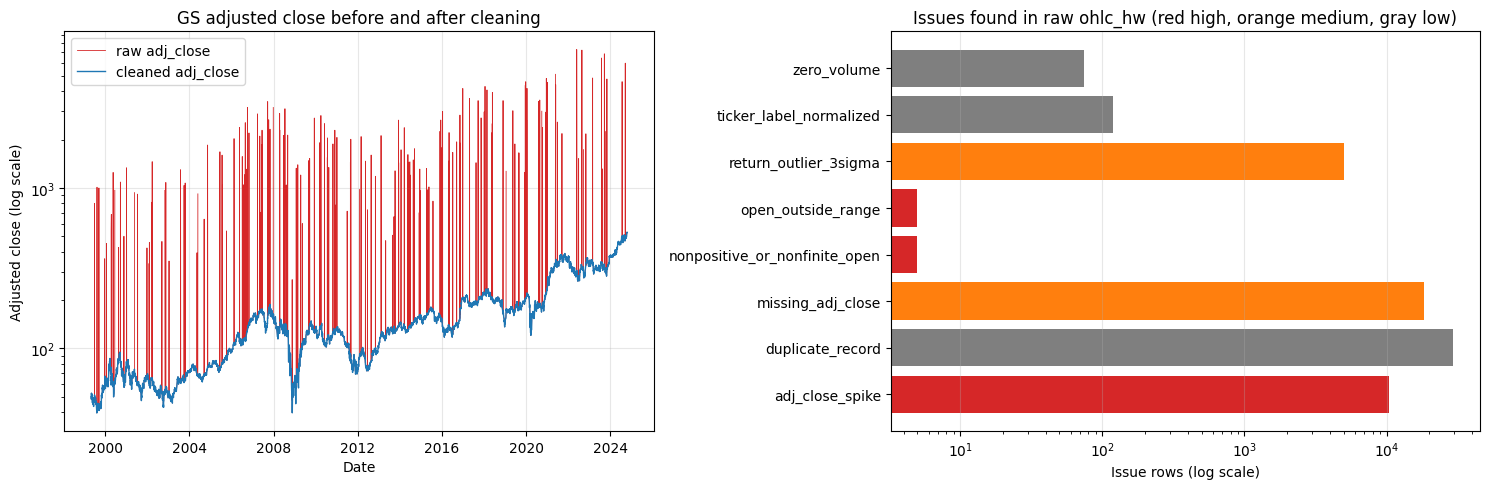

In [26]:
example = "GS"
before = (normalize_labels(raw).query("ticker == @example")
          .drop_duplicates(subset=VALUE_COLS).sort_values("ts"))
after = cleaned.query("ticker == @example")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(pd.to_datetime(before["ts"]), before["adj_close"], color="tab:red", lw=0.6, label="raw adj_close")
ax.plot(pd.to_datetime(after["ts"]), after["adj_close"], color="tab:blue", lw=1, label="cleaned adj_close")
ax.set(yscale="log", title=f"{example} adjusted close before and after cleaning",
       xlabel="Date", ylabel="Adjusted close (log scale)")
ax.legend()
ax.grid(alpha=0.3)

counts = quality_report.groupby(["issue_type", "severity"], observed=True).size().reset_index(name="rows")
colors = counts["severity"].map({"high": "tab:red", "medium": "tab:orange", "low": "tab:gray"})
axes[1].barh(counts["issue_type"], counts["rows"], color=colors)
axes[1].set(xscale="log", title="Issues found in raw ohlc_hw (red high, orange medium, gray low)",
            xlabel="Issue rows (log scale)")
axes[1].grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## Summary

| | Rows |
|---|---|
| Raw `ohlc_hw` | 397,711 |
| Exact duplicates removed | 29,460 |
| Rows with no raw prices dropped | 0 |
| Quarantined (`ohlc_hw_quarantine`) | 5 |
| **Retained in `ohlc_hw_cleaned`** | **368,246** |

- **Tickers:** 150 marked-up labels normalized to 30 tickers. The original label is kept in `raw_ticker`, and the label mapping is saved as `ohlc_hw_ticker_audit`.
- **`adj_close`:** 28,791 values rebuilt from a date-specific reference factor times the cleaned close. That's 18,374 missing values plus 10,417 corrupted ones, multiplied by 4x to 24x. The spike detector found every corrupted value with no false alarms, without using the reference.
- **Quarantined:** CVX, JNJ, MCD, MRK and PG each have `open = 0` on their first trading day, with no earlier close to repair from.
- **Kept with a flag:** 5,057 three-sigma return outliers (review flags, not deletions) and 74 zero-volume days.
- **Checked and found clean:** missing trading days, conflicting keys, missing raw prices or volume, and `high < close` or `low > close`. The injected examples show that each of those detectors and repairs works.
- **Validation:** the cleaned table passes every check, both in memory and after reading it back from the database. The raw table is unchanged.

The full diagnosis made before any repair is saved as `ohlc_hw_quality_report`: 63,512 issue rows with severity.